# Chest X-ray14: ¿los modelos miran donde está la lesión? Localización con cajas delimitadoras

**Autor:** Alfredo Gallegos Lopez, Universidad Panamericana, Aguascalientes. Proyecto final de Deep Learning (extensión).

En el paper, la interpretabilidad era **cualitativa** (unos pocos ejemplos de Grad-CAM). Aquí se mide de forma **cuantitativa**: ChestX-ray14 incluye `BBox_List_2017.csv`, con 984 cajas dibujadas por radiólogos sobre 880 imágenes (8 hallazgos). Para cada caja se calcula el mapa de cada modelo **para la clase real** y se mide si el mapa cae dentro de la caja.

- **Modelos:** los 4 entrenados con el dataset completo (`ChestXray14_112k_bajo_consumo.ipynb`), con los pesos de su mejor época, guardados en `checkpoints/112k/`. No se reentrena nada.
- **Métodos de mapa:**
  - Grad-CAM de DenseNet121, ResNet18 y MaxViT-T;
  - Grad-CAM del ViT-B/16, adaptado a sus parches de 14×14;
  - *attention rollout* del ViT, que no depende de la clase;
  - un **ensemble de mapas**: el promedio de los 4 Grad-CAM.
- **Métricas:**
  - *Pointing game*: ¿el punto de máxima activación cae dentro de la caja? Es la métrica estándar para mapas de saliencia en radiografías.
  - *Energía en la caja*: qué fracción de la activación total queda dentro.
- **Líneas base:**
  - *punto al azar*, cuyo acierto esperado es el área relativa de la caja;
  - *centro de la imagen*, que siempre apunta al centro. Es una línea base fuerte para hallazgos centrales como Cardiomegaly.
- **Conjunto principal:** solo las imágenes del **conjunto de prueba** del split por paciente (las mismas de la corrida de 112k), que ningún modelo vio al entrenar. Las 880 imágenes se reportan aparte como referencia.

Requisitos: `archive.zip` (para las etiquetas y las cajas), la caché `images_256/` y los checkpoints de `checkpoints/112k/`. Los tres se generan al correr `ChestXray14_112k_bajo_consumo.ipynb`.

## 1. Setup

In [1]:
import json
import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torchvision import models, transforms
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

SEED = 42
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

PROJECT_ROOT = Path(".").resolve()
ARCHIVE_PATH = PROJECT_ROOT / "archive.zip"
IMAGES_DIR = PROJECT_ROOT / "images_256"            # cache del dataset completo (la misma entrada que vieron los modelos)
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints" / "112k"
RESULTS_DIR = PROJECT_ROOT / "results" / "localizacion"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
for p in (ARCHIVE_PATH, IMAGES_DIR, CHECKPOINT_DIR):
    assert p.exists(), f"Falta {p}: corre antes ChestXray14_112k_bajo_consumo.ipynb"

# Mismos valores que la corrida de 112k (necesarios para reconstruir exactamente su split por paciente)
N_SAMPLES = 112120
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15
IMG_SIZE = 224
ORIG_SIZE = 1024   # las radiografias originales (y las coordenadas de las cajas) son de 1024x1024

DISEASE_LABELS = [
    "Atelectasis", "Cardiomegaly", "Effusion", "Infiltration", "Mass",
    "Nodule", "Pneumonia", "Pneumothorax", "Consolidation", "Edema",
    "Emphysema", "Fibrosis", "Pleural_Thickening", "Hernia",
]
NUM_CLASSES = len(DISEASE_LABELS)
MODEL_NAMES = ["densenet121", "resnet18", "vit_b_16", "maxvit_t"]

Using device: cuda


## 2. Cajas delimitadoras y split por paciente

Se reconstruye el split por paciente de la corrida de 112k con el mismo código y la misma semilla, para saber cuáles cajas caen en el conjunto de prueba. En el CSV de cajas, "Infiltrate" equivale a la clase "Infiltration".

In [2]:
with zipfile.ZipFile(ARCHIVE_PATH) as zf:
    names = zf.namelist()
    df_labels = pd.read_csv(zf.open([n for n in names if n.lower().endswith("data_entry_2017.csv")][0]))
    df_bbox = pd.read_csv(zf.open([n for n in names if n.lower().endswith("bbox_list_2017.csv")][0]))

# Split por paciente identico al de ChestXray14_112k_bajo_consumo.ipynb (In [3] y In [6])
df_sample = df_labels.sample(n=min(N_SAMPLES, len(df_labels)), random_state=SEED).reset_index(drop=True)
patients = df_sample["Patient ID"].unique()
np.random.default_rng(SEED).shuffle(patients)
imgs_per_patient = df_sample["Patient ID"].value_counts().reindex(patients).to_numpy()
cum_frac = np.cumsum(imgs_per_patient) / len(df_sample)
patient_split = dict(zip(patients, np.where(cum_frac <= TRAIN_FRAC, "train",
                                            np.where(cum_frac <= TRAIN_FRAC + VAL_FRAC, "val", "test"))))
split_of_image = dict(zip(df_sample["Image Index"], df_sample["Patient ID"].map(patient_split)))

df_bbox = df_bbox.iloc[:, :6]
df_bbox.columns = ["image", "label", "x", "y", "w", "h"]
df_bbox["label"] = df_bbox["label"].replace({"Infiltrate": "Infiltration"})
assert set(df_bbox["label"]) <= set(DISEASE_LABELS)
df_bbox["cls"] = df_bbox["label"].map(DISEASE_LABELS.index)
df_bbox["split"] = df_bbox["image"].map(split_of_image)
df_bbox["box_area_frac"] = (df_bbox["w"] * df_bbox["h"]) / ORIG_SIZE ** 2

print(f"{len(df_bbox)} cajas en {df_bbox['image'].nunique()} imagenes")
print(pd.crosstab(df_bbox["label"], df_bbox["split"], margins=True))

984 cajas en 880 imagenes
split         test  train  val  All
label                              
Atelectasis     21    125   34  180
Cardiomegaly    29     92   25  146
Effusion        15    122   16  153
Infiltration    11     95   17  123
Mass            11     64   10   85
Nodule          11     55   13   79
Pneumonia       17     87   16  120
Pneumothorax    13     74   11   98
All            128    714  142  984


## 3. Modelos entrenados con 112k

Se reconstruye cada modelo con la misma `build_model` de los notebooks principales y se cargan los pesos de su **mejor época** (`best_state` del checkpoint).

In [3]:
def freeze_all(module):
    for p in module.parameters():
        p.requires_grad = False


def build_model(name):
    # Misma arquitectura que en los notebooks de entrenamiento (fine-tuning parcial); aqui solo se cargan pesos.
    if name == "densenet121":
        model = models.densenet121(weights=None)
        model.classifier = nn.Linear(model.classifier.in_features, NUM_CLASSES)
    elif name == "resnet18":
        model = models.resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    elif name == "vit_b_16":
        model = models.vit_b_16(weights=None)
        model.heads.head = nn.Linear(model.heads.head.in_features, NUM_CLASSES)
    elif name == "maxvit_t":
        model = models.maxvit_t(weights=None)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, NUM_CLASSES)
    else:
        raise ValueError(name)
    return model


trained = {}
for name in MODEL_NAMES:
    ckpt = torch.load(CHECKPOINT_DIR / f"{name}.pt", map_location="cpu", weights_only=False)
    model = build_model(name)
    model.load_state_dict(ckpt["best_state"])
    model.eval()
    trained[name] = model
    print(f"{name}: pesos de la epoca {ckpt['best_epoch'] + 1} (val_loss {ckpt['best_val_loss']:.4f})")

densenet121: pesos de la epoca 2 (val_loss 0.1548)


resnet18: pesos de la epoca 2 (val_loss 0.1523)


vit_b_16: pesos de la epoca 2 (val_loss 0.1554)


maxvit_t: pesos de la epoca 4 (val_loss 0.1550)


## 4. Mapas de activación

- **Grad-CAM** sobre la última capa/etapa de cada CNN y del híbrido, con la **clase real** de la caja como objetivo.
- **ViT:** Grad-CAM sobre la normalización del último bloque, reacomodando los 196 tokens de parches en una rejilla de 14×14 (se descarta el token `[CLS]`), más el *attention rollout* de los 12 bloques.
- **Ensemble de mapas:** promedio de los 4 Grad-CAM, cada uno normalizado a [0, 1].

Todos los mapas quedan en 224×224, la resolución de entrada del modelo.

In [4]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


def vit_reshape(tensor, height=14, width=14):
    # [batch, 1 + 196, dim] -> [batch, dim, 14, 14] (sin el token CLS), para que Grad-CAM trate al ViT como mapa espacial
    result = tensor[:, 1:, :].reshape(tensor.size(0), height, width, tensor.size(2))
    return result.permute(0, 3, 1, 2)


CAM_LAYERS = {
    "densenet121": (lambda m: [m.features.norm5], None),
    "resnet18": (lambda m: [m.layer4[-1]], None),
    "vit_b_16": (lambda m: [m.encoder.layers[-1].ln_1], vit_reshape),
    "maxvit_t": (lambda m: [m.blocks[-1]], None),
}


def gradcam_map(name, x, cls):
    model = trained[name].to(device)
    layer_fn, reshape = CAM_LAYERS[name]
    with GradCAM(model=model, target_layers=layer_fn(model), reshape_transform=reshape) as cam:
        m = cam(input_tensor=x, targets=[ClassifierOutputTarget(cls)])[0]
    with torch.no_grad():
        prob = torch.sigmoid(model(x))[0, cls].item()
    return m, prob


def vit_rollout_map(x):
    vit = trained["vit_b_16"].to(device)
    with torch.no_grad():
        tokens = vit._process_input(x)
        tokens = torch.cat([vit.class_token.expand(tokens.shape[0], -1, -1), tokens], dim=1)
        h = vit.encoder.dropout(tokens + vit.encoder.pos_embedding)
        attentions = []
        for block in vit.encoder.layers:
            y = block.ln_1(h)
            y, attn = block.self_attention(y, y, y, need_weights=True, average_attn_weights=True)
            h = h + block.dropout(y)
            h = h + block.mlp(block.ln_2(h))
            attentions.append(attn[0])
        identity = torch.eye(attentions[0].shape[0], device=x.device)
        rollout = identity
        for attn in attentions:
            a = 0.5 * attn + 0.5 * identity
            rollout = (a / a.sum(dim=-1, keepdim=True)) @ rollout
    v = rollout[0, 1:].reshape(14, 14).cpu().numpy()
    v = np.array(Image.fromarray(v.astype(np.float32)).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
    return (v - v.min()) / (v.max() - v.min() + 1e-8)


def normalize(m):
    return (m - m.min()) / (m.max() - m.min() + 1e-8)

## 5. Métricas de localización

Para cada caja (llevada de 1024 a 224 px) y cada mapa se calcula:

- **Pointing game:** ¿el píxel de máxima activación cae dentro de la caja? (acierto = 1, fallo = 0)
- **Energía en la caja:** fracción de la activación total que cae dentro de la caja.

Líneas base: **punto al azar**, cuyo acierto esperado es el área relativa de la caja (la misma cifra es la energía esperada de un mapa uniforme), y **centro de la imagen**, que acierta si la caja contiene el centro.

In [5]:
METHODS = ["densenet121", "resnet18", "vit_b_16", "maxvit_t", "ensemble_cam", "vit_rollout"]
records, cache = [], {}
t0 = time.time()
for i, row in df_bbox.iterrows():
    s = IMG_SIZE / ORIG_SIZE
    x0, y0 = row["x"] * s, row["y"] * s
    x1, y1 = (row["x"] + row["w"]) * s, (row["y"] + row["h"]) * s
    mask = np.zeros((IMG_SIZE, IMG_SIZE), dtype=bool)
    mask[int(np.floor(y0)):int(np.ceil(y1)), int(np.floor(x0)):int(np.ceil(x1))] = True

    img = Image.open(IMAGES_DIR / row["image"]).convert("RGB")
    x = eval_transform(img).unsqueeze(0).to(device)
    maps, probs = {}, {}
    for name in MODEL_NAMES:
        maps[name], probs[name] = gradcam_map(name, x, int(row["cls"]))
    maps["ensemble_cam"] = np.mean([normalize(maps[n]) for n in MODEL_NAMES], axis=0)
    maps["vit_rollout"] = vit_rollout_map(x)
    cache[i] = {k: v.astype(np.float16) for k, v in maps.items()}

    for method in METHODS:
        m = maps[method]
        py, px = np.unravel_index(np.argmax(m), m.shape)
        records.append({
            "box": i, "image": row["image"], "label": row["label"], "split": row["split"], "method": method,
            "pointing_hit": bool(mask[py, px]),
            "energy_in_box": float(m[mask].sum() / (m.sum() + 1e-8)),
            "prob_true_class": probs.get(method, np.nan),
        })
    records.append({"box": i, "image": row["image"], "label": row["label"], "split": row["split"], "method": "baseline_random",
                    "pointing_hit": float(row["box_area_frac"]), "energy_in_box": float(row["box_area_frac"]), "prob_true_class": np.nan})
    records.append({"box": i, "image": row["image"], "label": row["label"], "split": row["split"], "method": "baseline_center",
                    "pointing_hit": bool(mask[IMG_SIZE // 2, IMG_SIZE // 2]), "energy_in_box": np.nan, "prob_true_class": np.nan})
    if (i + 1) % 200 == 0:
        print(f"  {i + 1}/{len(df_bbox)} cajas ({time.time() - t0:.0f}s)")

for m in trained.values():
    m.cpu()
res = pd.DataFrame(records)
res["pointing_hit"] = res["pointing_hit"].astype(float)
print(f"Listo: {len(df_bbox)} cajas x {len(METHODS)} metodos en {time.time() - t0:.0f}s")

..\.venv-rocm\Lib\site-packages\torch\nn\functional.py:6717: UserWarning: 1Torch was not compiled with memory efficient attention. (Triggered internally at B:\src\torch\aten\src\ATen\native\transformers\hip\sdp_utils.cpp:862.)
  attn_output = scaled_dot_product_attention(


  200/984 cajas (77s)


  400/984 cajas (137s)


  600/984 cajas (198s)


  800/984 cajas (260s)


Listo: 984 cajas x 6 metodos en 317s


## 6. Resultados

Tasa de acierto del *pointing game* con intervalo de confianza al 95% (Wilson), y energía media dentro de la caja. Primero en el **conjunto de prueba** (principal) y después en las 880 imágenes (referencia).

In [6]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return (c - h, c + h)


ORDER = ["densenet121", "resnet18", "vit_b_16", "maxvit_t", "ensemble_cam", "vit_rollout", "baseline_center", "baseline_random"]


def summarize(df):
    rows = []
    for method in ORDER:
        d = df[df["method"] == method]
        n, k = len(d), d["pointing_hit"].sum()
        lo, hi = wilson(k, n) if method != "baseline_random" else (np.nan, np.nan)
        rows.append({"metodo": method, "n_cajas": n, "pointing_game": k / n if n else np.nan, "IC95_lo": lo, "IC95_hi": hi,
                     "energia_en_caja": d["energy_in_box"].mean()})
    return pd.DataFrame(rows).set_index("metodo")


summary_test = summarize(res[res["split"] == "test"])
summary_all = summarize(res)
print("== Conjunto de prueba (principal)")
display(summary_test.round(3))
print("== Las 880 imagenes (referencia; incluye imagenes de entrenamiento)")
display(summary_all.round(3))

per_class = (res[res["split"] == "test"].pivot_table(index="label", columns="method", values="pointing_hit", aggfunc="mean")[ORDER])
per_class.insert(0, "n_cajas", res[(res["split"] == "test") & (res["method"] == "resnet18")].groupby("label").size())
print("== Pointing game por hallazgo (prueba)")
display(per_class.round(2))

== Conjunto de prueba (principal)


,n_cajas,pointing_game,IC95_lo,IC95_hi,energia_en_caja
metodo,,,,,
densenet121,128,0.281,0.211,0.365,0.188
resnet18,128,0.203,0.143,0.281,0.174
vit_b_16,128,0.281,0.211,0.365,0.172
maxvit_t,128,0.258,0.190,0.340,0.158
ensemble_cam,128,0.336,0.260,0.421,0.189
vit_rollout,128,0.000,0.000,0.029,0.055
baseline_center,128,0.289,0.218,0.373,NaN
baseline_random,128,0.088,NaN,NaN,0.088


== Las 880 imagenes (referencia; incluye imagenes de entrenamiento)


,n_cajas,pointing_game,IC95_lo,IC95_hi,energia_en_caja
metodo,,,,,
densenet121,984,0.221,0.196,0.247,0.148
resnet18,984,0.198,0.174,0.224,0.144
vit_b_16,984,0.236,0.210,0.263,0.140
maxvit_t,984,0.217,0.193,0.244,0.129
ensemble_cam,984,0.304,0.276,0.333,0.150
vit_rollout,984,0.006,0.003,0.013,0.047
baseline_center,984,0.218,0.194,0.245,NaN
baseline_random,984,0.075,NaN,NaN,0.075


== Pointing game por hallazgo (prueba)


method,n_cajas,densenet121,resnet18,vit_b_16,maxvit_t,ensemble_cam,vit_rollout,baseline_center,baseline_random
label,,,,,,,,,
Atelectasis,21,0.10,0.05,0.00,0.19,0.00,0.0,0.14,0.03
Cardiomegaly,29,0.79,0.52,0.90,0.52,0.97,0.0,0.93,0.18
Effusion,15,0.20,0.33,0.07,0.27,0.33,0.0,0.00,0.07
Infiltration,11,0.18,0.18,0.27,0.18,0.18,0.0,0.18,0.10
Mass,11,0.27,0.18,0.00,0.09,0.18,0.0,0.09,0.04
Nodule,11,0.09,0.00,0.09,0.00,0.00,0.0,0.00,0.01
Pneumonia,17,0.06,0.00,0.29,0.29,0.29,0.0,0.24,0.12
Pneumothorax,13,0.08,0.08,0.00,0.15,0.08,0.0,0.00,0.07


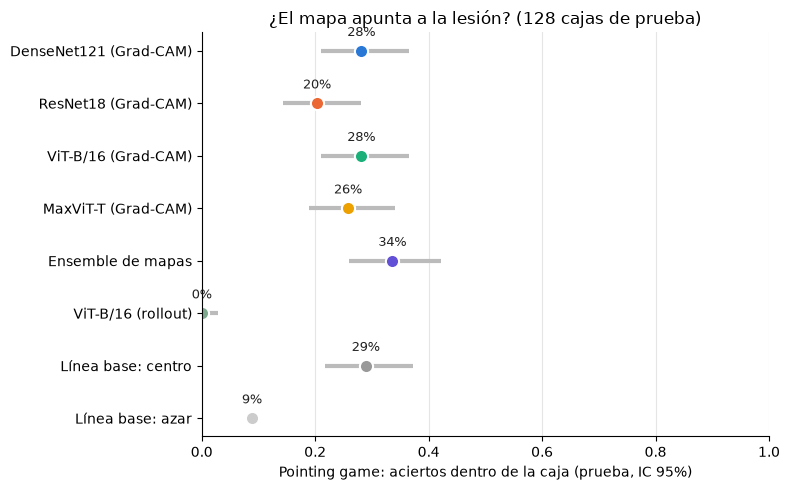

In [7]:
COLORS = {"densenet121": "#2a78d6", "resnet18": "#eb6834", "vit_b_16": "#1baf7a", "maxvit_t": "#eda100",
          "ensemble_cam": "#6250d6", "vit_rollout": "#7fa98f", "baseline_center": "#999999", "baseline_random": "#cccccc"}
LABELS = {"densenet121": "DenseNet121 (Grad-CAM)", "resnet18": "ResNet18 (Grad-CAM)", "vit_b_16": "ViT-B/16 (Grad-CAM)",
          "maxvit_t": "MaxViT-T (Grad-CAM)", "ensemble_cam": "Ensemble de mapas", "vit_rollout": "ViT-B/16 (rollout)",
          "baseline_center": "Línea base: centro", "baseline_random": "Línea base: azar"}

fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(ORDER))[::-1]
vals = summary_test.loc[ORDER, "pointing_game"].to_numpy()
lo = summary_test.loc[ORDER, "IC95_lo"].to_numpy()
hi = summary_test.loc[ORDER, "IC95_hi"].to_numpy()
for yi, method, v, l, h in zip(y, ORDER, vals, lo, hi):
    if not np.isnan(l):
        ax.hlines(yi, l, h, color="#bbbbbb", linewidth=3, zorder=1)
    ax.scatter(v, yi, s=90, color=COLORS[method], edgecolors="white", linewidths=1.5, zorder=2)
    ax.text(v, yi + 0.28, f"{v:.0%}", ha="center", fontsize=9, color="#222222")
ax.set_yticks(y)
ax.set_yticklabels([LABELS[m] for m in ORDER])
ax.set_xlim(0, 1)
ax.set_xlabel("Pointing game: aciertos dentro de la caja (prueba, IC 95%)")
ax.set_title(f"¿El mapa apunta a la lesión? ({int(summary_test.loc['resnet18', 'n_cajas'])} cajas de prueba)")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.grid(axis="x", color="#e5e5e5")
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "pointing_game.png", dpi=150)
plt.show()

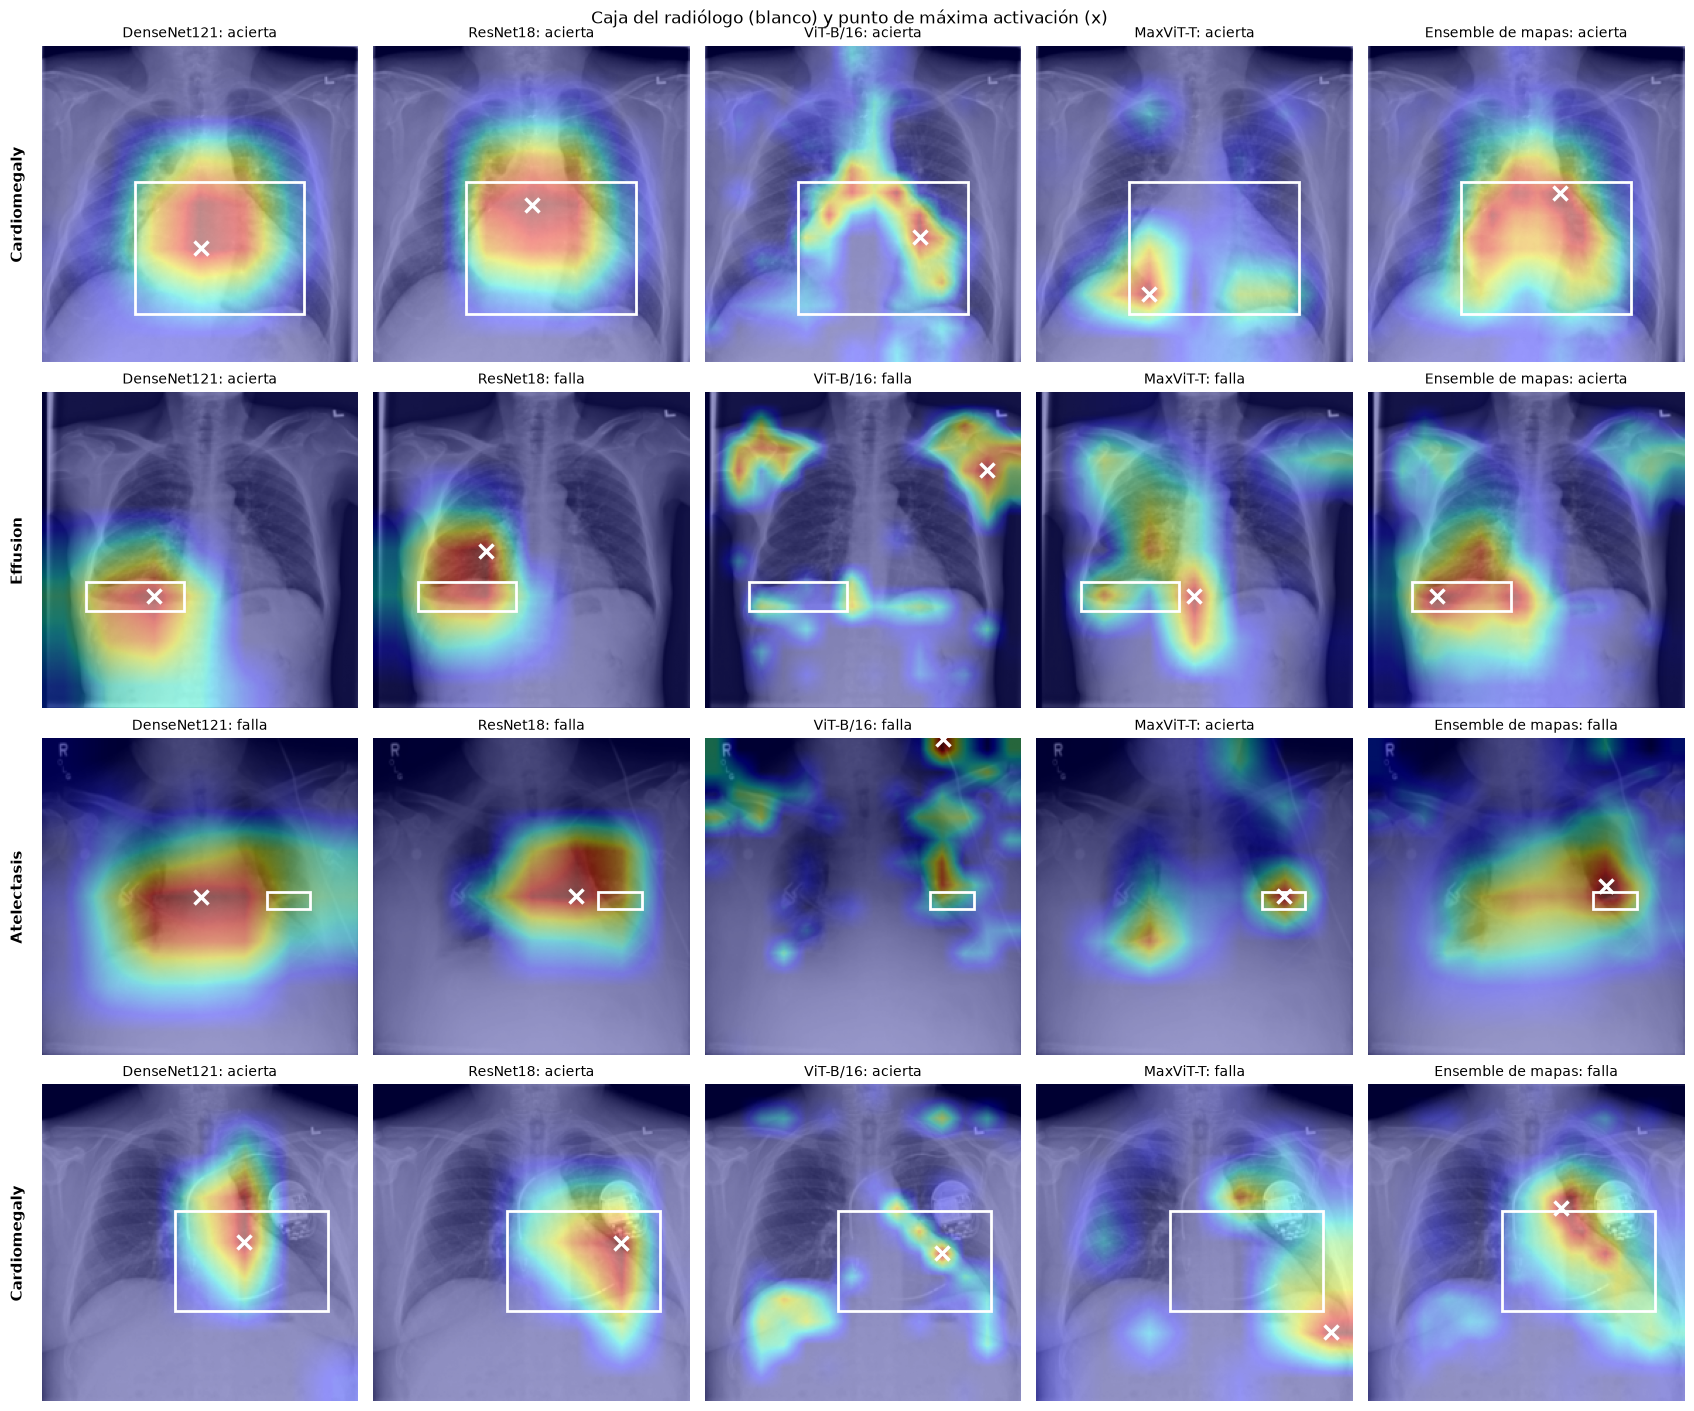

In [8]:
# Ejemplos: un acierto y un fallo del ensemble de mapas en prueba, con la caja del radiologo dibujada
test_boxes = res[(res["split"] == "test") & (res["method"] == "ensemble_cam")]
picks = []
for hit in (True, False):
    cand = test_boxes[test_boxes["pointing_hit"] == float(hit)]
    picks += list(cand.drop_duplicates("label").head(2)["box"])
fig, axes = plt.subplots(len(picks), 5, figsize=(17, 3.6 * len(picks)), squeeze=False)
for r, i in enumerate(picks):
    row = df_bbox.loc[i]
    img = np.array(Image.open(IMAGES_DIR / row["image"]).convert("L").resize((IMG_SIZE, IMG_SIZE))) / 255.0
    s = IMG_SIZE / ORIG_SIZE
    for c, method in enumerate(["densenet121", "resnet18", "vit_b_16", "maxvit_t", "ensemble_cam"]):
        ax = axes[r, c]
        ax.imshow(img, cmap="gray")
        ax.imshow(cache[i][method].astype(np.float32), cmap="jet", alpha=0.4)
        ax.add_patch(plt.Rectangle((row["x"] * s, row["y"] * s), row["w"] * s, row["h"] * s, fill=False, edgecolor="white", linewidth=2))
        m = cache[i][method].astype(np.float32)
        py, px = np.unravel_index(np.argmax(m), m.shape)
        ax.plot(px, py, marker="x", color="white", markersize=10, markeredgewidth=2.5)
        hit = res[(res["box"] == i) & (res["method"] == method)]["pointing_hit"].iloc[0]
        ax.set_title(f"{LABELS[method].split(' (')[0]}: {'acierta' if hit else 'falla'}", fontsize=10)
        ax.axis("off")
    axes[r, 0].text(-12, IMG_SIZE / 2, row["label"], rotation=90, va="center", ha="right", fontsize=11, fontweight="bold")
plt.suptitle("Caja del radiólogo (blanco) y punto de máxima activación (x)", fontsize=12)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "localizacion_ejemplos.png", dpi=110)
plt.show()

## 7. Exportar resultados

In [9]:
def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else float(o)
    if isinstance(o, np.integer):
        return int(o)
    return o


out = {
    "config": {"modelos": "checkpoints/112k (mejor epoca)", "img_size": IMG_SIZE, "seed": SEED,
               "cajas_total": int(len(df_bbox)), "cajas_prueba": int((df_bbox["split"] == "test").sum())},
    "prueba": summary_test.reset_index().to_dict(orient="records"),
    "todas_880": summary_all.reset_index().to_dict(orient="records"),
    "prueba_por_hallazgo": per_class.reset_index().to_dict(orient="records"),
}
with open(RESULTS_DIR / "localizacion_metrics.json", "w", encoding="utf-8") as f:
    json.dump(to_jsonable(out), f, indent=2, ensure_ascii=False)
res.to_csv(RESULTS_DIR / "localizacion_por_caja.csv", index=False)
print("Guardado en", RESULTS_DIR.relative_to(PROJECT_ROOT))

Guardado en results\localizacion
